In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [4]:
df = pd.read_csv('sales_data_sample.csv',encoding='latin1')
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [5]:
df.isnull().sum()

ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE               0
dtype: int64

In [6]:
X = df[['QUANTITYORDERED','PRICEEACH','SALES']]
scaler = StandardScaler()
X_s = scaler.fit_transform(X)

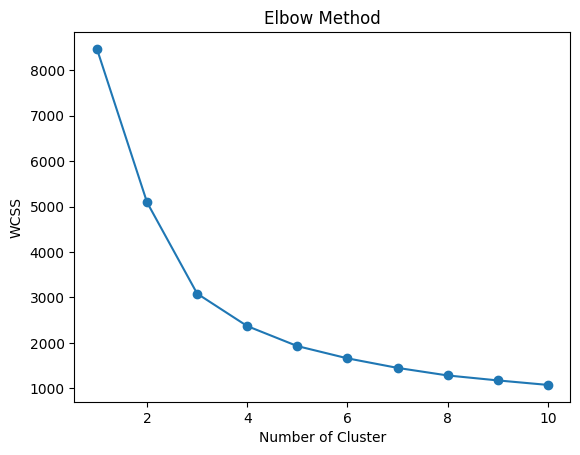

In [10]:
wcss = []
for k in range(1,11):
    kmeans = KMeans(n_clusters = k,random_state=42,n_init=10)
    kmeans.fit(X_s)
    wcss.append(kmeans.inertia_)
   
plt.plot(range(1,11),wcss,marker='o')
plt.title("Elbow Method")
plt.xlabel('Number of Cluster')
plt.ylabel('WCSS')
plt.show()
    

In [ ]:
kmeans = KMeans(n_clusters=3,random_state=42,n_init=10)
df['cluster'] = kmeans.fit_predict(X_s)
print(df[['QUANTITY ORDERED','PRICE EACH','SALES','cluster']].head())

   QUANTITYORDERED  PRICEEACH    SALES  cluster
0               30      95.70  2871.00        2
1               34      81.35  2765.90        2
2               41      94.74  3884.34        1
3               45      83.26  3746.70        1
4               49     100.00  5205.27        1


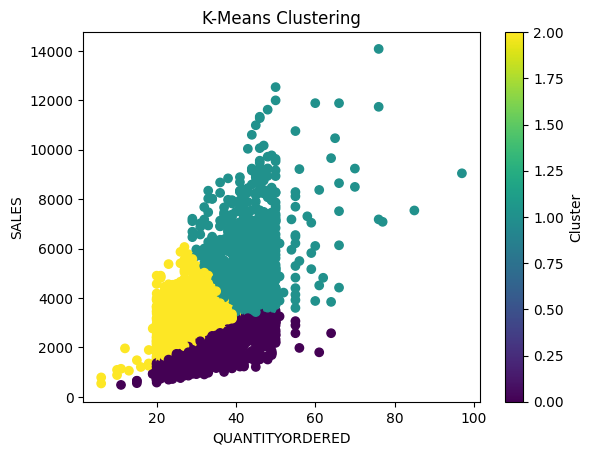

In [14]:
plt.scatter(df['QUANTITYORDERED'], df['SALES'],
            c=df['cluster'], cmap='viridis')

plt.xlabel('QUANTITYORDERED')
plt.ylabel('SALES')
plt.title('K-Means Clustering')

plt.colorbar(label='Cluster')
plt.show()